# 07 · Step 7: The Nudge engine, one engine on three datasets (gate K7)
**What we are building:** a reusable targeted-intervention engine (`nudge_engine.py`, in this folder). Give it a company's customers plus one randomized test, and for every customer it predicts the extra value of every option (nothing, reminder, discount, reward…) and recommends the best.

**Why one engine, not one model per dataset:** a trained model only knows the customers it learned from. The *engine* (same code, same steps) is what transfers: each company retrains it on its own data. Proof: below, the identical engine runs on three very different businesses.

| Dataset | Business question | Options | Value to maximise |
|---|---|---|---|
| X5 (Russian grocery, real) | **Whom to contact?** | message / nothing | bought (1/0) minus the message cost |
| Starbucks (simulated) | **Which offer?** | 10 offers / nothing | spend minus reward paid |
| Hillstrom (US e-commerce, real) | **Which message?** | men's email / women's email / nothing | spend |

**The standard input:** one row per customer contact: `features` (known before the contact) · `arm` (option given, at random) · `value` (outcome) · optional `option_cost` and `group` (customer id).

**How the engine decides:** (1) one doubly robust uplift model per option; (2) start from the best option on average; (3) switch to a customer's personal best only if it beats the default by a **safety margin** that the engine learns from the data. If personalising does not reliably pay, the margin goes to infinity and the engine falls back to the best single option, so it is never worse than the best blanket policy.

## Cell 0 · Setup

In [1]:
import pandas as pd, numpy as np, duckdb, time, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from pathlib import Path
from nudge_engine import NudgeEngine, check_balance, average_effects, evaluate_policies, split_by_group
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20); pd.set_option('display.max_colwidth', 70)
X5 = Path('..') / 'data_x5' / 'features'; RAW = Path('..') / 'data_offers' / 'raw'
SUMMARY = []
def show(res):
    display(res.drop(columns='mix').round(4)); display(res[['mix']])

## Dataset 1 · X5: whom to contact?
One option (an SMS) or nothing. When a message is free, sending it to everyone is fine (the average effect is positive). When it **costs money**, the engine should contact only customers whose predicted uplift beats the cost.
- **Message cost** is expressed in the same unit as the value (purchase probability): a cost of 0.033 means one message costs as much as 3.3% of the margin on a purchase. At 0.033 messaging everyone exactly breaks even on average (the average lift is 3.3 points).
- For a yes/no decision the rule is simply *contact if predicted uplift > cost*, so the margin is fixed at 0 here.

In [2]:
t0 = time.time()
d = duckdb.sql(f"SELECT * FROM '{(X5 / 'customer_profiles.parquet').as_posix()}' WHERE in_experiment = 1").df()
d = pd.concat([d, pd.get_dummies(d.gender, prefix='gender').astype(int)], axis=1)
XF = [c for c in d.columns if c not in {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}]
d[XF] = d[XF].astype('float32'); d['option'] = np.where(d.treatment_flg == 1, 'message', 'none'); d['bought'] = d.target.astype(float)
print('largest balance gap:', round(check_balance(d, XF, 'option', 'none').abs().max().max(), 4))
display(average_effects(d, 'option', 'none', 'bought').round(4))
tr, te = split_by_group(d, 'client_id')
x5_engine = NudgeEngine(XF, 'option', 'none', 'bought', margin=0).fit(tr)
print(f'engine fitted in {time.time() - t0:.0f}s')

largest balance gap: 0.0125


,extra_value,low95,high95,rows
option,,,,
message,0.0332,0.029,0.0375,99981


engine fitted in 131s


,cost,policy,value,low95,high95,vs_everyone,vs_low95,vs_high95,share_messaged_%
0,0.000,Message nobody,0.6038,0.5974,0.6111,-0.0298,-0.0395,-0.0213,0.0000
1,0.000,Message everyone,0.6338,0.6275,0.6403,NaN,NaN,NaN,100.0000
2,0.000,Nudge engine,0.6312,0.6240,0.6376,-0.0026,-0.0057,0.0003,89.5921
3,0.020,Message nobody,0.6038,0.5974,0.6111,-0.0098,-0.0195,-0.0013,0.0000
4,0.020,Message everyone,0.6138,0.6075,0.6203,NaN,NaN,NaN,100.0000
5,0.020,Nudge engine,0.6201,0.6132,0.6265,0.0064,0.0003,0.0118,57.4860
6,0.033,Message nobody,0.6038,0.5974,0.6111,0.0032,-0.0065,0.0117,0.0000
7,0.033,Message everyone,0.6008,0.5945,0.6073,NaN,NaN,NaN,100.0000
8,0.033,Nudge engine,0.6143,0.6075,0.6203,0.0136,0.0062,0.0201,38.2424
9,0.050,Message nobody,0.6038,0.5974,0.6111,0.0202,0.0105,0.0287,0.0000


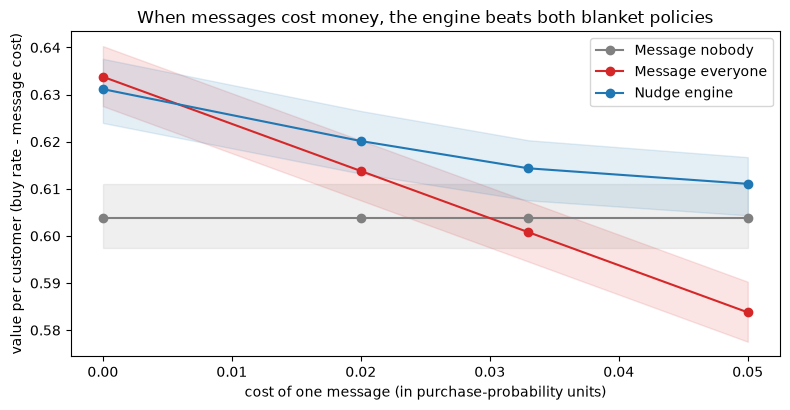

In [3]:
rows = []
for cost in [0.0, 0.02, 0.033, 0.05]:
    oc = {'message': cost}; x5_engine.with_costs(oc, tr); rec = x5_engine.recommend(te)
    res = evaluate_policies(te, 'option', 'bought', {'Message nobody': ['none'] * len(te), 'Message everyone': ['message'] * len(te),
                                                     'Nudge engine': rec.values}, x5_engine.prop, oc, baseline='Message everyone')
    for p in res.index:
        rows.append({'cost': cost, 'policy': p, 'value': res.loc[p, 'value_per_customer'], 'low95': res.loc[p, 'low95'], 'high95': res.loc[p, 'high95'],
                     'vs_everyone': res.loc[p].get('vs_baseline', 0), 'vs_low95': res.loc[p].get('vs_low95', 0), 'vs_high95': res.loc[p].get('vs_high95', 0),
                     'share_messaged_%': 100 * (rec == 'message').mean() if p == 'Nudge engine' else (100 if p == 'Message everyone' else 0)})
X5R = pd.DataFrame(rows); display(X5R.round(4))
fig, ax = plt.subplots(figsize=(8, 4.2))
for p, c in [('Message nobody', 'grey'), ('Message everyone', 'tab:red'), ('Nudge engine', 'tab:blue')]:
    s = X5R[X5R.policy == p]; ax.plot(s.cost, s.value, marker='o', color=c, label=p)
    ax.fill_between(s.cost, s.low95, s.high95, color=c, alpha=0.12)
ax.set_xlabel('cost of one message (in purchase-probability units)'); ax.set_ylabel('value per customer (buy rate - message cost)')
ax.set_title('When messages cost money, the engine beats both blanket policies'); ax.legend(); plt.tight_layout(); plt.show()
e33 = X5R[(X5R.cost == 0.033) & (X5R.policy == 'Nudge engine')].iloc[0]
n33 = X5R[(X5R.cost == 0.033) & (X5R.policy == 'Message nobody')].iloc[0]
SUMMARY.append({'dataset': 'X5', 'question': 'whom to contact (message cost 0.033)', 'best blanket policy': 'message nobody (0.6038)',
                'engine value': round(e33.value, 4), 'engine vs best blanket': f"{e33.value - n33.value:+.4f}; vs message everyone {e33.vs_everyone:+.4f} ({e33.vs_low95:+.4f} to {e33.vs_high95:+.4f})",
                'engine choice': f"message {e33['share_messaged_%']:.0f}%"})

## Dataset 2 · Starbucks: which offer?
Same customer-wave table as Step 6, plus each customer's **history before the wave** (past spend and visits, past offers received, viewed and completed). Options = the 10 individual offers or nothing. Value = spend in 72 hours minus the reward paid.

In [4]:
t0 = time.time()
pf = pd.read_json(RAW / 'starbucks_portfolio.json.gz', lines=True, compression='gzip')
pr = pd.read_json(RAW / 'starbucks_profile.json.gz', lines=True, compression='gzip')
tr_ = pd.read_json(RAW / 'starbucks_transcript.json.gz', lines=True, compression='gzip')
tr_['offer_id'] = tr_.value.apply(lambda v: v.get('offer id', v.get('offer_id'))); tr_['amount'] = tr_.value.apply(lambda v: v.get('amount'))
tr_['reward'] = tr_.value.apply(lambda v: v.get('reward'))
pf['offer_name'] = pf.offer_type.str.upper().str[:4] + ' ' + pf.difficulty.astype(str) + '/' + pf.reward.astype(str) + ' ' + pf.duration.astype(int).astype(str) + 'd'
WAVES, WIN = [0, 168, 336, 408, 504, 576], 72
x = pd.MultiIndex.from_product([pr.id, WAVES], names=['person', 'time']).to_frame(index=False)
x = x.merge(tr_[tr_.event == 'offer received'][['person', 'time', 'offer_id']], on=['person', 'time'], how='left')
x['option'] = x.offer_id.map(dict(zip(pf.id, pf.offer_name))).fillna('none')
tx = tr_[tr_.event == 'transaction'][['person', 'time', 'amount']].rename(columns={'time': 't'})
m = x[['person', 'time']].merge(tx, on='person')
x = x.merge(m[(m.t >= m.time) & (m.t < m.time + WIN)].groupby(['person', 'time']).amount.sum().rename('spend').reset_index(), on=['person', 'time'], how='left')
comp = tr_[tr_.event == 'offer completed'][['person', 'time', 'offer_id', 'reward']].rename(columns={'time': 'tc', 'reward': 'paid'})
mc = x[['person', 'time', 'offer_id']].dropna().merge(comp, on=['person', 'offer_id']); mc = mc[(mc.tc >= mc.time) & (mc.tc < mc.time + WIN)]
x = x.merge(mc.groupby(['person', 'time']).paid.sum().reset_index(), on=['person', 'time'], how='left')
x[['spend', 'paid']] = x[['spend', 'paid']].fillna(0); x['net'] = x.spend - x.paid
# history BEFORE each wave
past = m[m.t < m.time].groupby(['person', 'time']).agg(past_spend=('amount', 'sum'), past_tx=('amount', 'size'), last_tx=('t', 'max')).reset_index()
x = x.merge(past, on=['person', 'time'], how='left'); x['hours_since_tx'] = x.time - x.last_tx
x[['past_spend', 'past_tx']] = x[['past_spend', 'past_tx']].fillna(0)
x['past_spend_per_day'] = np.where(x.time > 0, x.past_spend / (x.time / 24).clip(lower=1), np.nan)
ev = tr_[tr_.event.isin(['offer received', 'offer viewed', 'offer completed'])][['person', 'time', 'event', 'offer_id']].merge(
     pf[['id', 'offer_type']].rename(columns={'id': 'offer_id'}), on='offer_id')
me = x[['person', 'time']].merge(ev.rename(columns={'time': 'te'}), on='person'); me = me[me.te < me.time]
for evn, short in [('offer received', 'rec'), ('offer viewed', 'view'), ('offer completed', 'comp')]:
    for ot in ['bogo', 'discount', 'informational']:
        c = me[(me.event == evn) & (me.offer_type == ot)].groupby(['person', 'time']).size().rename(f'past_{short}_{ot}').reset_index()
        x = x.merge(c, on=['person', 'time'], how='left')
PC = [c for c in x.columns if c.startswith('past_') and c not in ('past_spend', 'past_tx', 'past_spend_per_day')]; x[PC] = x[PC].fillna(0)
p = pr.rename(columns={'id': 'person'}).copy(); p.loc[p.age == 118, 'age'] = np.nan
p['member_days'] = (pd.Timestamp('2018-07-27') - pd.to_datetime(p.became_member_on.astype(str))).dt.days
p['female'] = (p.gender == 'F').astype(float).where(p.gender.notna()); p['missing_profile'] = p.gender.isna().astype(int)
x = x.merge(p[['person', 'age', 'income', 'member_days', 'female', 'missing_profile']], on='person'); x['wave'] = x.time
SF = ['age', 'income', 'member_days', 'female', 'missing_profile', 'wave', 'past_spend', 'past_tx', 'hours_since_tx', 'past_spend_per_day'] + PC
print(f'{len(x):,} customer-waves | {len(SF)} features | prepared in {time.time() - t0:.0f}s')
print('largest balance gap:', round(check_balance(x, SF, 'option', 'none').abs().max().max(), 4))
display(average_effects(x, 'option', 'none', 'net').round(2))

102,000 customer-waves | 19 features | prepared in 6s
largest balance gap: 0.0446


,extra_value,low95,high95,rows
option,,,,
DISC 10/2 10d,7.35,6.41,8.29,7597
DISC 7/3 7d,5.72,4.92,6.52,7646
BOGO 5/5 5d,4.92,3.96,5.87,7571
INFO 0/0 3d,4.68,3.92,5.43,7618
BOGO 10/10 5d,3.30,2.47,4.12,7593
BOGO 10/10 7d,2.82,2.01,3.63,7658
INFO 0/0 4d,2.73,2.00,3.46,7617
DISC 10/2 7d,2.54,1.78,3.29,7632
BOGO 5/5 7d,1.54,0.77,2.31,7677


In [5]:
t0 = time.time()
sb_tr, sb_te = split_by_group(x, 'person')
sb_tr_w = sb_tr.copy(); sb_tr_w['net'] = sb_tr_w.net.clip(sb_tr_w.net.quantile(0.01), sb_tr_w.net.quantile(0.99))   # tame extreme spenders
sb_engine = NudgeEngine(SF, 'option', 'none', 'net', group='person').fit(sb_tr_w)
print(f'fitted in {time.time() - t0:.0f}s | best single offer: {sb_engine.default}')
print('how much better must a personal choice look before overriding it? (value of each margin, learned on the build half)')
display(sb_engine.margin_scores.round(3).rename('policy value').to_frame().T)
print('chosen margin:', sb_engine.margin_mult)
best = sb_engine.default
pol = {'Send nothing': ['none'] * len(sb_te), 'Random offers (as in the test)': 'LOGGED', 'All reminders': ['INFO 0/0 3d'] * len(sb_te),
       f'Best single offer to all ({best})': [best] * len(sb_te),
       'Personalise always (no margin)': sb_engine.recommend(sb_te, margin_mult=0).values, 'Nudge engine': sb_engine.recommend(sb_te).values}
SBR = evaluate_policies(sb_te, 'option', 'net', pol, sb_engine.prop, baseline=f'Best single offer to all ({best})'); show(SBR)

fitted in 770s | best single offer: DISC 10/2 10d
how much better must a personal choice look before overriding it? (value of each margin, learned on the build half)


,0.00,0.10,0.25,0.50,1.00,2.00,inf
policy value,12.346,12.302,12.4,12.505,12.686,12.568,12.623


chosen margin: 1.0


,value_per_customer,low95,high95,vs_baseline,vs_low95,vs_high95
policy,,,,,,
Send nothing,7.4923,6.8326,8.2440,-8.5420,-11.0768,-6.5753
Random offers (as in the test),10.5331,10.0986,11.0000,-5.4968,-7.7342,-3.7953
All reminders,12.6016,11.3649,14.0162,-3.3993,-6.2003,-1.1650
Best single offer to all (DISC 10/2 10d),16.1038,14.2442,18.4402,NaN,NaN,NaN
Personalise always (no margin),14.4962,12.8474,16.3419,-1.6321,-3.4140,-0.1263
Nudge engine,16.1052,14.3106,18.3441,-0.0206,-0.3621,0.3269


,mix
policy,
Send nothing,none 100%
Random offers (as in the test),"none 25%, DISC 20/5 10d 8%, BOGO 5/5 7d 8%, BOGO 10/10 7d 8%"
All reminders,INFO 0/0 3d 100%
Best single offer to all (DISC 10/2 10d),DISC 10/2 10d 100%
Personalise always (no margin),"DISC 10/2 10d 35%, DISC 7/3 7d 19%, INFO 0/0 3d 18%, BOGO 5/5 5d 7%"
Nudge engine,"DISC 10/2 10d 95%, DISC 7/3 7d 2%, BOGO 5/5 5d 1%, INFO 0/0 3d 1%"


In [6]:
SUMMARY.append({'dataset': 'Starbucks', 'question': 'which offer', 'best blanket policy': f'{best} to all', 'engine value': round(SBR.loc['Nudge engine', 'value_per_customer'], 2),
                'engine vs best blanket': f"{SBR.loc['Nudge engine', 'vs_baseline']:+.2f} ({SBR.loc['Nudge engine', 'vs_low95']:+.2f} to {SBR.loc['Nudge engine', 'vs_high95']:+.2f})",
                'engine choice': SBR.loc['Nudge engine', 'mix']})

## Dataset 3 · Hillstrom: which message?
Options: men's email, women's email or nothing. Value = spend in the next 2 weeks (real data).

In [7]:
t0 = time.time()
h = pd.read_csv(RAW / 'hillstorm_no_indices.csv.gz')
h = pd.concat([h, pd.get_dummies(h.zip_code, prefix='area').astype(int), pd.get_dummies(h.channel, prefix='chan').astype(int)], axis=1)
HF = ['recency', 'history', 'mens', 'womens', 'newbie'] + [c for c in h.columns if c.startswith(('area_', 'chan_'))]
h['cid'] = np.arange(len(h))
print('largest balance gap:', round(check_balance(h, HF, 'segment', 'No E-Mail').abs().max().max(), 4))
display(average_effects(h, 'segment', 'No E-Mail', 'spend').round(3))
h_tr, h_te = split_by_group(h, 'cid')
h_engine = NudgeEngine(HF, 'segment', 'No E-Mail', 'spend', group='cid').fit(h_tr)
print(f'fitted in {time.time() - t0:.0f}s | best single email: {h_engine.default} | chosen margin: {h_engine.margin_mult}')
pol = {'No email': ['No E-Mail'] * len(h_te), 'Random (as in the test)': 'LOGGED', "All men's email": ['Mens E-Mail'] * len(h_te),
       "All women's email": ['Womens E-Mail'] * len(h_te), "Rule: men's buyers get men's, others women's": np.where(h_te.mens == 1, 'Mens E-Mail', 'Womens E-Mail'),
       'Personalise always (no margin)': h_engine.recommend(h_te, margin_mult=0).values, 'Nudge engine': h_engine.recommend(h_te).values}
HR = evaluate_policies(h_te, 'segment', 'spend', pol, h_engine.prop, baseline="All men's email"); show(HR)
SUMMARY.append({'dataset': 'Hillstrom', 'question': 'which message', 'best blanket policy': "men's email to all", 'engine value': round(HR.loc['Nudge engine', 'value_per_customer'], 3),
                'engine vs best blanket': f"{HR.loc['Nudge engine', 'vs_baseline']:+.3f} ({HR.loc['Nudge engine', 'vs_low95']:+.3f} to {HR.loc['Nudge engine', 'vs_high95']:+.3f})",
                'engine choice': HR.loc['Nudge engine', 'mix']})

largest balance gap: 0.0137


,extra_value,low95,high95,rows
option,,,,
Mens E-Mail,0.770,0.485,1.055,21307
Womens E-Mail,0.424,0.169,0.680,21387


fitted in 104s | best single email: Mens E-Mail | chosen margin: inf


,value_per_customer,low95,high95,vs_baseline,vs_low95,vs_high95
policy,,,,,,
No email,0.6341,0.2790,1.0329,-0.6395,-1.3045,-0.0392
Random (as in the test),0.9399,0.6863,1.1972,-0.3204,-0.7028,0.0588
All men's email,1.2690,0.8386,1.7523,NaN,NaN,NaN
All women's email,0.9101,0.5138,1.3856,-0.3286,-1.0192,0.3562
"Rule: men's buyers get men's, others women's",1.0659,0.6834,1.5854,-0.1794,-0.6061,0.2898
Personalise always (no margin),1.1324,0.6956,1.6386,-0.1338,-0.5838,0.2835
Nudge engine,1.2690,0.8386,1.7523,0.0000,0.0000,0.0000


,mix
policy,
No email,No E-Mail 100%
Random (as in the test),"Mens E-Mail 34%, Womens E-Mail 33%, No E-Mail 33%"
All men's email,Mens E-Mail 100%
All women's email,Womens E-Mail 100%
"Rule: men's buyers get men's, others women's","Mens E-Mail 55%, Womens E-Mail 45%"
Personalise always (no margin),"Mens E-Mail 48%, Womens E-Mail 37%, No E-Mail 15%"
Nudge engine,Mens E-Mail 100%


## Summary and K7 verdict
- **Never worse than the best blanket policy:** the engine's range against it must include or exceed zero on all three datasets.
- **Beats both blanket policies when contact costs money** (X5 at cost 0.033).
- **Personalising the offer type** is reported honestly: it is kept only where it pays.

In [8]:
display(pd.DataFrame(SUMMARY).set_index('dataset'))
x5e = X5R[(X5R.cost == 0.033) & (X5R.policy == 'Nudge engine')].iloc[0]
x5n = X5R[(X5R.cost == 0.033) & (X5R.policy == 'Message nobody')].iloc[0]
checks = {
  'Never worse than best blanket policy (Starbucks)': SBR.loc['Nudge engine', 'vs_high95'] >= 0,
  'Never worse than best blanket policy (Hillstrom)': HR.loc['Nudge engine', 'vs_high95'] >= 0,
  'Beats message-everyone when messages cost 0.033 (X5)': x5e.vs_low95 > 0,
  'Beats message-nobody when messages cost 0.033 (X5)': x5e.value > x5n.value,
}
for k, v in checks.items(): print(f'{"PASS" if v else "FAIL"}  {k}')
print('\nK7 VERDICT:', 'PASS' if all(checks.values()) else 'REVIEW')

,question,best blanket policy,engine value,engine vs best blanket,engine choice
dataset,,,,,
X5,whom to contact (message cost 0.033),message nobody (0.6038),0.6143,+0.0106; vs message everyone +0.0136 (+0.0062 to +0.0201),message 38%
Starbucks,which offer,DISC 10/2 10d to all,16.1100,-0.02 (-0.36 to +0.33),"DISC 10/2 10d 95%, DISC 7/3 7d 2%, BOGO 5/5 5d 1%, INFO 0/0 3d 1%"
Hillstrom,which message,men's email to all,1.2690,+0.000 (+0.000 to +0.000),Mens E-Mail 100%


PASS  Never worse than best blanket policy (Starbucks)
PASS  Never worse than best blanket policy (Hillstrom)
PASS  Beats message-everyone when messages cost 0.033 (X5)
PASS  Beats message-nobody when messages cost 0.033 (X5)

K7 VERDICT: PASS


## Your notes
- Why does the engine fall back to one offer for everyone on Starbucks and Hillstrom?
- Where does targeting create the most value, and why does the message cost matter?
- How would an Indian company use this engine on its own data?